# Lab 6 – Localization: model vs real trajectory

Odometry of the "54" trajectory, logged by the same program in the TRIK Studio simulator and on the real robot.

Log format: one line per sample, no header, `x,y,time` (x, y in m, time in ms).

- `odometry_data_sim.txt` – simulator
- `odometry_data_real.txt` – real robot

In [7]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select both txt files

Saving odometry_data_real.txt to odometry_data_real (2).txt
Saving odometry_data_sim.txt to odometry_data_sim (2).txt


In [8]:
x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

## 1. Trajectories on one plot

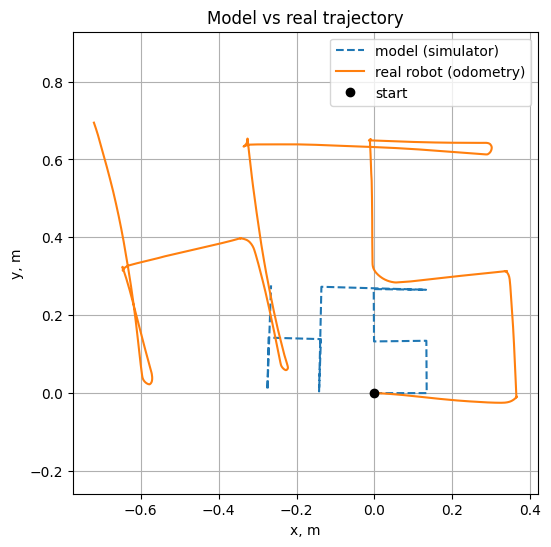

In [9]:
plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

## 2. Error over time

The simulator log is resampled onto the real-robot timestamps.

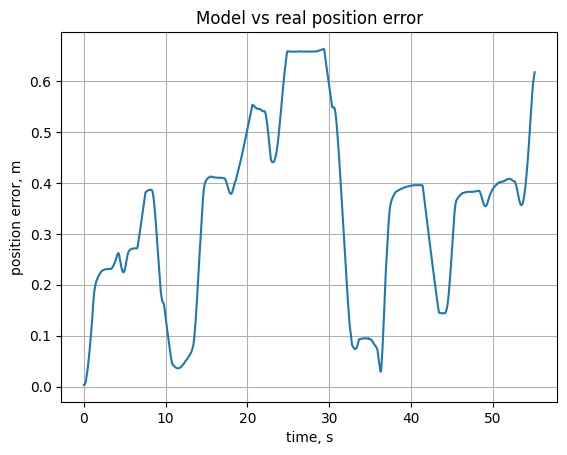

Final odometry error (sim vs real): 0.618 m
Max error: 0.664 m


In [10]:
t_s, t_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.3f} m')
print(f'Max error: {err.max():.3f} m')

## 3. Measured end point

After the real run, measure the robot's final position with a tape, in the odometry frame: origin at the start point, x along the robot's initial heading, y to its left.

In [12]:
x_meas, y_meas = -0.83, 0.80           # measured

print(f'Odometry end point: ({x_r[-1]:.3f}, {y_r[-1]:.3f}) m')
print(f'Measured end point: ({x_meas:.3f}, {y_meas:.3f}) m')
print(f'Odometry vs measured: {np.hypot(x_r[-1] - x_meas, y_r[-1] - y_meas):.3f} m')

Odometry end point: (-0.720, 0.694) m
Measured end point: (-0.830, 0.800) m
Odometry vs measured: 0.152 m


## 4. Discussion

The real trajectory is about 3x larger than the simulated one because the simulated robot has smaller wheels and a lower speed, so most of the 0.62 m final sim-vs-real error is scale rather than drift. In shape, the real path diverges from the first segment (−5° instead of 0°): each turn is off by 1–12°, while the sim's are within 1.2°, and after the second reverse turn every heading is 10–25° off. The main cause is unequal motors. The robot drifts left by 1–10° on every straight segment, which matches the faster right wheel measured in Week 5, and because heading error dominates, these few degrees grow into tens of centimetres of position error. Turn inaccuracy adds on it as well. The robot cannot detect wheel slip or a wrong r or B: its odometry ends at (−0.720, 0.694) m, while the tape measurement gives (-0.830, 0.80) m, a difference of 0.152 m that the robot has no way of noticing.